# Unexpected productivity shock, cohort by cohort

The companion to `demand_shock_cohorts.ipynb`, on the same steady state
(`steady_state.ipynb`) and the same commitment structure, with the shock hitting $A_t$ instead
of the household's taste for consumption.

## Where $A$ enters, and when

In

$$y_{i,t}(\Delta)=\kappa^{\Delta}\bigl(\Delta+B_tN_i\bigr)\bigl(A_t\,l_{t,i}\bigr)$$

both shifters are dated $t$ — the date the **labour is applied**, not the date the goods
arrive.  A batch delivering at $t$ was started at $t-\tau_i$, so it was made with $A_{t-\tau_i}$:

$$y_{i,t}=\kappa^{\tau_i}(\tau_i+N_i)\,A_{t-\tau_i}\,l_{i,t-\tau_i}
\;=\;\zeta_i\,A_{t-\tau_i}\,l_{i,t-\tau_i}.$$

## The shock

$A_0=0.97$, and $A_t=1$ for every $t\ge1$: **the shock hits exactly the batches that start
production at $t=0$, and nothing else.**  Every batch already in the pipeline was made under
the old technology, and every batch started from $t=1$ on is made under the old technology
again.

The consequence is the point of the exercise.  A batch started at $t=0$ by producer $i$ is
delivered at $t=\tau_i$.  So a shock that lasts one period is *delivered* over the whole
inventory-duration distribution:

| producer | hit at | delivers the damaged goods at | share of output |
|---|---|---|---|
| $\tau_i=0$ | $t=0$ | $t=0$ | 0.9 % |
| $\tau_i=1$ | $t=0$ | $t=1$ | 21.9 % |
| $\tau_i=2$ | $t=0$ | $t=2$ | 44.7 % |
| $\tau_i=3$ | $t=0$ | $t=3$ | 20.3 % |
| … | | | |

Only 0.9 % of output is even capable of registering the shock on impact.  The rest arrives
later, and the aggregate response is hump-shaped with a trough at $t=2$ — the mode of the
calibrated $\tau$ distribution — rather than on impact.

## $\Delta$ does not move with $A$

Worth noting because it is not obvious: the delay solves
$\max_\Delta(\prod\delta_j)\kappa^{\Delta}(\Delta+N_i)$, and $A_t$ multiplies $l$ linearly at the
hiring date, so it is common across $\Delta$ and drops out.  A TFP shock has **no direct effect
on $\tau_i$** — only the induced path of demand would move it, and that margin is held shut
here as in the demand notebook.  (A $B_t$ shock would be different: $B$ sits inside
$(\Delta+B_tN_i)$ and does change the optimal delay.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Parameters and calibration

Identical to the other two notebooks.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

sigma = 5.0; gamma = 2.0; eta = 2.0; chi = 1.0
mu      = sigma / (sigma - 1)
beta    = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1   = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho     = 1 / beta - 1
PHI_YA  = (1 + eta) / (gamma + eta)
PHI_LA  = (1 - gamma) / (gamma + eta)

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

TVALS   = tau.astype(int).to_numpy()
N_ARRAY = np.array(N)
kappa   = c

print(f'kappa = {kappa:.6f}   n = {len(TVALS)}   tau in [0, {TVALS.max()}]   '
      f'counts = {np.bincount(TVALS)}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_51024/205254120.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = 0.901802   n = 269   tau in [0, 13]   counts = [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]


## 2. The model, in real terms

The demand notebook solved for the nominal wage and output.  That works, but it carries a
near-null direction: scaling every $W_t$ and $P_t$ together changes nothing real, and the
solver has to fight it.  Since we know the nominal side is neutral here — the commitment is in
quantities, not in nominal prices — it is cleaner to solve the real system directly.

Write $\omega_t=W_t/P_t$ and $1+r_t=(1+i_t)P_t/P_{t+1}$.  A free producer's *relative* price is

$$\frac{p_{i,t}}{P_t}
=\mu\,\frac{\omega_{t-\tau_i}}{\zeta_i A_{t-\tau_i}}\prod_{j=t-\tau_i}^{t-1}(1+r_j),$$

which contains nothing nominal.  The system is then

| | |
|---|---|
| Euler *defines* $r_t$ | $1+r_t=\dfrac{\Xi_tC_t^{-\gamma}}{\beta_{hh}\Xi_{t+1}C_{t+1}^{-\gamma}}$ |
| CES index | $\sum_{i\,\text{free}}\bigl(\tfrac{p_{i,t}}{P_t}\bigr)^{1-\sigma}+\sum_{i\,\text{locked}}\bigl(\tfrac{y_i^{ss}}{Y_t}\bigr)^{\frac{\sigma-1}{\sigma}}=1$ |
| labour supply | $\omega_t=\chi L_t^{\eta}C_t^{\gamma}$ |
| clearing | $C_t=Y_t$,  $\;L_t=\sum_i y_{i,t+\tau_i}/(\zeta_iA_t)$ |

with unknowns $\{\omega_t,Y_t\}$.  Output is parameterised as $Y_t=\underline Y_t+e^{v_t}$, where
$\underline Y_t$ is the CES aggregate that the committed goods deliver on their own — a floor no
Newton step can cross.  (It does not bind for this shock, but it is a real property of the
model: at $t=0$ output cannot fall more than 1.19 % however bad the news.)  Section 4 checks
that this reproduces the demand notebook's nominal solver to machine precision.

`Economy.solve` takes an arbitrary $A$ path, so persistent or permanent variants are one line
away; this notebook runs only the one-period shock.

In [3]:
class Economy:
    '''Time-to-produce economy with a given cross-section of delays.'''

    def __init__(self, tvals, N_array, T=60):
        self.tvals = np.asarray(tvals, int)
        self.N     = np.asarray(N_array, float)
        self.n     = len(self.tvals)
        self.T     = T
        self.taumax = int(self.tvals.max())
        self.zeta  = kappa ** self.tvals * (self.tvals + self.N)
        self.free  = self.tvals[None, :] <= np.arange(T)[:, None]
        self.tpt   = np.arange(T)[:, None] + self.tvals[None, :]   # delivery date of batch t
        self.ss0   = self.ss(1.0)
        # locked-side constant of the CES index, and the floor it implies for Y
        self.S     = np.array([np.sum(self.ss0['y'][~self.free[t]] ** ((sigma - 1) / sigma))
                               for t in range(T)])
        self.Yfloor = self.S ** (sigma / (sigma - 1))

    def ss(self, A):
        '''Steady state at productivity level A (levels; see steady_state.ipynb).'''
        z     = beta ** self.tvals * self.zeta * A
        A_til = np.sum(z ** (sigma - 1)) ** (1 / (sigma - 1))
        Lam   = np.sum(z ** (sigma - 1) * beta ** self.tvals)
        Theta = A_til ** sigma / Lam
        L     = (A_til / (mu * chi * Theta ** gamma)) ** (1 / (gamma + eta))
        Y     = Theta * L
        q     = A_til / z                                   # relative price p_i / P
        y     = q ** (-sigma) * Y
        return dict(A=A, z=z, A_til=A_til, Theta=Theta, L=L, Y=Y, C=Y,
                    omega=A_til / mu, q=q, y=y, l=y / (self.zeta * A))

    def allocation(self, omega, Y, A_path, ssT, xi):
        T, n, pad = self.T, self.n, self.taumax + 2
        om  = np.r_[omega,  np.full(pad, ssT['omega'])]
        Yx  = np.r_[Y,      np.full(pad, ssT['Y'])]
        Ax  = np.r_[A_path, np.full(pad, A_path[-1])]
        xix = np.r_[xi,     np.zeros(pad)]

        r = np.exp(xix[:T] - xix[1:T + 1]) * (Yx[1:T + 1] / Yx[:T]) ** gamma / beta_hh - 1.0
        R = np.r_[1.0, np.cumprod(1.0 + r)]                 # R[k] = prod_{j<k} (1 + r_j)

        q = np.empty((T, n)); y = np.empty((T, n)); gap = np.empty(T)
        for t in range(T):
            f = self.free[t]; s = t - self.tvals[f]
            q_f = mu * om[s] * (R[t] / R[s]) / (self.zeta[f] * Ax[s])   # A at the HIRING date
            q[t, f]  = q_f
            y[t, f]  = q_f ** (-sigma) * Yx[t]
            y[t, ~f] = self.ss0['y'][~f]                    # committed, made pre-shock
            q[t, ~f] = (self.ss0['y'][~f] / Yx[t]) ** (-1 / sigma)
            gap[t]   = np.sum(q_f ** (1 - sigma)) + self.S[t] * Yx[t] ** ((1 - sigma) / sigma) - 1.0

        yx = np.vstack([y, np.tile(ssT['y'], (pad, 1))])
        l  = yx[self.tpt, np.arange(n)] / (self.zeta * Ax[:T, None])    # A at the hiring date
        return dict(q=q, y=y, l=l, L=l.sum(axis=1), r=r, omega=omega, Y=Y, C=Y,
                    A=A_path, ces_gap=gap, ssT=ssT)

    def _resid(self, u, A_path, ssT, xi):
        omega = np.exp(u[:self.T]); Y = self.Yfloor + np.exp(u[self.T:])
        a = self.allocation(omega, Y, A_path, ssT, xi)
        r_ls = np.log(omega) - (np.log(chi) + eta * np.log(a['L']) + gamma * np.log(Y))
        return np.r_[r_ls, a['ces_gap']]

    def solve(self, A_path=None, xi=None):
        T = self.T
        A_path = np.ones(T) if A_path is None else np.asarray(A_path, float)
        xi     = np.zeros(T) if xi is None else np.asarray(xi, float)
        ssT = self.ss(A_path[-1])                           # terminal SS at the terminal A
        u0  = np.r_[np.full(T, np.log(self.ss0['omega'])),
                    np.log(self.ss0['Y'] - self.Yfloor)]
        s   = root(self._resid, u0, args=(A_path, ssT, xi), method='hybr', tol=1e-13)
        a   = self.allocation(np.exp(s.x[:T]), self.Yfloor + np.exp(s.x[T:]), A_path, ssT, xi)
        a.update(ok=s.success, res=float(np.max(np.abs(s.fun))), xi=xi)
        return a


E   = Economy(TVALS, N_ARRAY)
T   = E.T
ss0 = E.ss0
print(f'initial SS:  Y = C = {ss0["Y"]:.6f}   L = {ss0["L"]:.6f}   W/P = {ss0["omega"]:.6f}')
print(f'floor on Y_0 set by the committed goods: '
      f'{100*np.log(E.Yfloor[0]/ss0["Y"]):+.4f} %   (t=1: {100*np.log(E.Yfloor[1]/ss0["Y"]):+.2f} %)')

initial SS:  Y = C = 11.287917   L = 0.410776   W/P = 21.500001
floor on Y_0 set by the committed goods: -1.1914 %   (t=1: -32.37 %)


## 3. The shock

`A_PATH` is the whole experiment: 3 % off productivity for the batches started at $t=0$, and
nothing else.

In [4]:
A_SHOCK = 0.97

A_PATH = np.r_[A_SHOCK, np.ones(T - 1)]     # only the batches started at t = 0 are hit
sol    = E.solve(A_PATH)

print(f"A path (per cent): {np.round(100*np.log(A_PATH[:6]), 4)}  ...")
print(f"converged = {sol['ok']},  max |residual| = {sol['res']:.2e}")
print(f"terminal steady state is the initial one: "
      f"Y {100*np.log(sol['ssT']['Y']/ss0['Y']):+.2e} %")

A path (per cent): [-3.0459  0.      0.      0.      0.      0.    ]  ...
converged = True,  max |residual| = 1.15e-14
terminal steady state is the initial one: Y +0.00e+00 %


## 4. Checks

In [5]:
print('Which producers have moved off the steady-state quantity:')
for t in range(6):
    mv = np.where(np.abs(sol['y'][t] / ss0['y'] - 1) > 1e-10)[0]
    print(f'   t={t}:  {len(mv):>3} producers,  taus = {sorted(set(TVALS[mv]))}')
assert all(np.allclose(sol['y'][t][TVALS > t], ss0['y'][TVALS > t]) for t in range(T))
assert all(set(TVALS[np.abs(sol['y'][t] / ss0['y'] - 1) > 1e-10]) <= set(range(t + 1))
           for t in range(T))
print('\n   assertion passed: at every t, exactly the producers with tau <= t deviate.\n')

zero = E.solve()
agg  = np.sum(sol['y'] ** ((sigma - 1) / sigma), axis=1) ** (sigma / (sigma - 1))
print(f"   CES aggregator == Y                        max|dlog| = "
      f"{np.max(np.abs(np.log(agg / sol['Y']))):.2e}")
print(f"   CES index sums to 1                        max|gap|  = "
      f"{np.max(np.abs(sol['ces_gap'])):.2e}")
print(f"   demand curve for every i, t                max|diff| = "
      f"{np.max(np.abs(sol['y'] - sol['q'] ** (-sigma) * sol['Y'][:, None])):.2e}")
print(f"   labour supply  w = chi L^eta C^gamma       max|dlog| = "
      f"{np.max(np.abs(np.log(sol['omega'] / (chi * sol['L'] ** eta * sol['C'] ** gamma)))):.2e}")
print(f"   no shock reproduces the steady state       max|dlog| = "
      f"{max(np.max(np.abs(np.log(zero['Y']/ss0['Y']))), np.max(np.abs(np.log(zero['L']/ss0['L'])))):.2e}")
print(f"   returns to the steady state by t = {T}      |dlogY_T| = "
      f"{abs(np.log(sol['Y'][-1]/ss0['Y'])):.2e}")

# the productivity loss really is confined to the batches started at t = 0:
# rebuild each producer's delivery from its own hiring-date A and check it back out
hire_A = np.where(np.arange(T)[:, None] - TVALS[None, :] == 0, A_SHOCK, 1.0)
implied = np.array([[sol['l'][t - TVALS[i], i] * E.zeta[i] * hire_A[t, i] if t >= TVALS[i]
                     else ss0['y'][i] for i in range(E.n)] for t in range(T)])
print(f"   y_i,t == zeta_i A_(t-tau) l_i,(t-tau)      max|dlog| = "
      f"{np.max(np.abs(np.log(implied / sol['y']))):.2e}")

# the real solver must reproduce the demand notebook's nominal solver
d = E.solve(np.ones(T), xi=np.r_[-0.01, np.zeros(T - 1)])
ref_Y = np.array([-0.0341, 0.0760, 0.0794, 0.0523, 0.0367, 0.0237])
ref_L = np.array([0.3957, -0.0423, -0.0288, -0.0191, -0.0123, -0.0080])
print(f"\n   cross-check vs demand_shock_cohorts.ipynb (nominal solver, 1 % demand shock;")
print(f"   reference values are that notebook's printed output, rounded to 4 dp):")
print(f"      Y  max|diff| = {np.max(np.abs(100*np.log(d['Y']/ss0['Y'])[:6] - ref_Y)):.2e} pp")
print(f"      L  max|diff| = {np.max(np.abs(100*np.log(d['L']/ss0['L'])[:6] - ref_L)):.2e} pp")

Which producers have moved off the steady-state quantity:
   t=0:    1 producers,  taus = [0]
   t=1:   32 producers,  taus = [0, 1]
   t=2:  129 producers,  taus = [0, 1, 2]
   t=3:  195 producers,  taus = [0, 1, 2, 3]
   t=4:  243 producers,  taus = [0, 1, 2, 3, 4]
   t=5:  261 producers,  taus = [0, 1, 2, 3, 4, 5]

   assertion passed: at every t, exactly the producers with tau <= t deviate.

   CES aggregator == Y                        max|dlog| = 5.22e-15
   CES index sums to 1                        max|gap|  = 4.11e-15
   demand curve for every i, t                max|diff| = 2.08e-17
   labour supply  w = chi L^eta C^gamma       max|dlog| = 1.13e-14
   no shock reproduces the steady state       max|dlog| = 2.44e-15
   returns to the steady state by t = 60      |dlogY_T| = 3.67e-13
   y_i,t == zeta_i A_(t-tau) l_i,(t-tau)      max|dlog| = 3.33e-16

   cross-check vs demand_shock_cohorts.ipynb (nominal solver, 1 % demand shock;
   reference values are that notebook's printed out

## 5. Aggregate response

Per cent from the steady state.  The benchmark line is the same economy with $\tau_i=0$ for
everyone: there the one-period shock is over in one period, and takes the full
$\phi_{YA}\log A=-2.28$ % on impact.

In [6]:
E0  = Economy(np.zeros_like(TVALS), N_ARRAY)          # no time to build
sol0 = E0.solve(A_PATH)
print(f"no-time-to-build benchmark: converged = {sol0['ok']}, "
      f"max |residual| = {sol0['res']:.2e}")

irf = pd.DataFrame({
    'Y = C %':  100 * np.log(sol['Y'] / ss0['Y']),
    'L %':      100 * np.log(sol['L'] / ss0['L']),
    'W/P %':    100 * np.log(sol['omega'] / ss0['omega']),
    'r %':      100 * sol['r'],
    'Y % no ttb': 100 * np.log(sol0['Y'] / E0.ss0['Y']),
    'producers still committed': (~E.free).sum(axis=1),
}, index=pd.Index(range(T), name='t')).iloc[:10]
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(irf)

dY = np.log(sol['Y'] / ss0['Y'])
print(f"impact  {100*dY[0]:+.4f} %   trough {100*dY.min():+.4f} % at t = {int(np.argmin(dY))}")
print(f"no time to build: {100*np.log(sol0['Y'][0]/E0.ss0['Y']):+.4f} % on impact, "
      f"back at steady state at t = 1")
print(f"cumulative output loss, sum of log deviations:  "
      f"time to produce {100*dY.sum():.4f} %   vs no time to build "
      f"{100*np.log(sol0['Y']/E0.ss0['Y']).sum():.4f} %")

no-time-to-build benchmark: converged = True, max |residual| = 1.33e-15


,Y = C %,L %,W/P %,r %,Y % no ttb,producers still committed
t,,,,,,
0,-0.0740,-0.6507,-1.4495,-0.1237,-2.2844,268
1,-0.6335,0.3520,-0.5630,0.9455,-0.0000,237
2,-0.6604,0.2389,-0.8431,1.4593,-0.0000,140
3,-0.4336,0.1583,-0.5506,1.2637,-0.0000,74
4,-0.3032,0.1018,-0.4028,1.2166,-0.0000,26
5,-0.1961,0.0659,-0.2604,1.1451,-0.0000,8
6,-0.1243,0.0430,-0.1627,1.0863,-0.0000,7
7,-0.0816,0.0282,-0.1069,1.0580,-0.0000,5
8,-0.0529,0.0185,-0.0688,1.0364,-0.0000,5


impact  -0.0740 %   trough -0.6604 % at t = 2
no time to build: -2.2844 % on impact, back at steady state at t = 1
cumulative output loss, sum of log deviations:  time to produce -2.6615 %   vs no time to build -2.2844 %


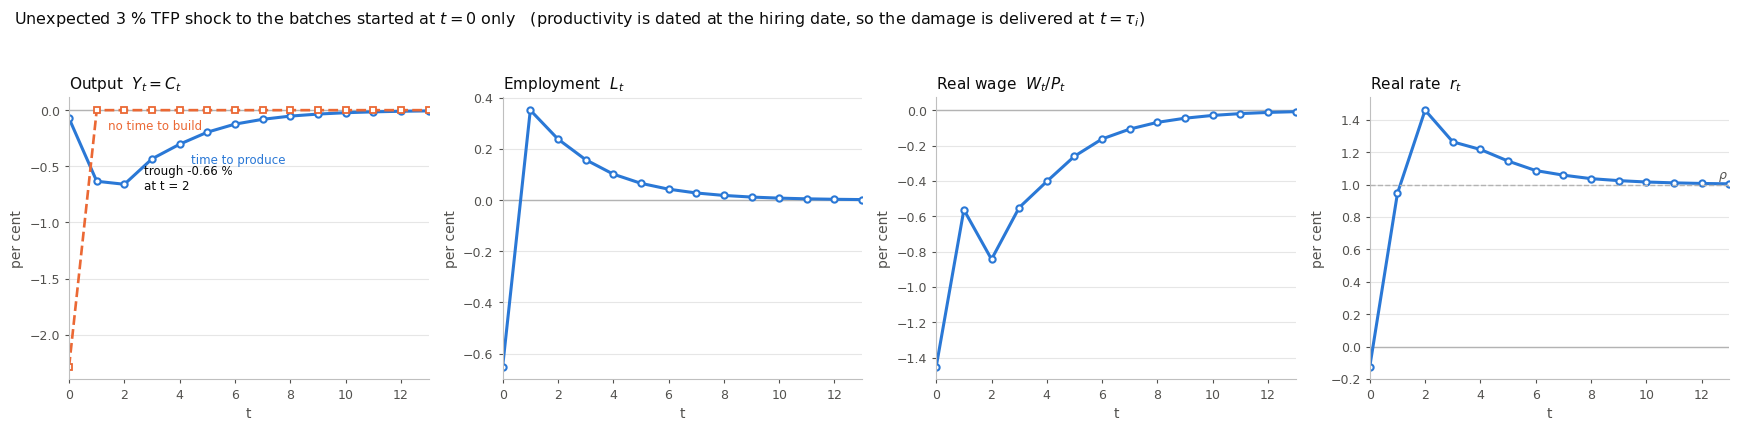

In [7]:
BLUE, ORANGE, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
H = 14

def style(ax):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    ax.grid(axis='y', color='0.9', lw=0.8); ax.set_axisbelow(True)
    ax.axhline(0, color='0.7', lw=1.0, zorder=1)
    ax.set_xlim(0, H - 1); ax.set_xlabel('t', color=MUTED)

t = np.arange(H)
panels = [('Output  $Y_t=C_t$',   100 * np.log(sol['Y'] / ss0['Y'])),
          ('Employment  $L_t$',   100 * np.log(sol['L'] / ss0['L'])),
          ('Real wage  $W_t/P_t$', 100 * np.log(sol['omega'] / ss0['omega'])),
          ('Real rate  $r_t$',    100 * sol['r'])]

fig, axes = plt.subplots(1, 4, figsize=(17.5, 4.1))
fig.patch.set_facecolor('white')
for j, (ax, (name, v)) in enumerate(zip(axes, panels)):
    style(ax)
    ax.plot(t, v[:H], color=BLUE, lw=2.2, marker='o', ms=4.5, markerfacecolor='white',
            markeredgecolor=BLUE, markeredgewidth=1.5)
    ax.set_title(name, color=INK, fontsize=11, loc='left')
    ax.set_ylabel('per cent', color=MUTED)
    if j == 0:
        v0 = 100 * np.log(sol0['Y'] / E0.ss0['Y'])
        ax.plot(t, v0[:H], color=ORANGE, lw=1.9, ls='--', marker='s', ms=4,
                markerfacecolor='white', markeredgecolor=ORANGE, markeredgewidth=1.3)
        ax.annotate('no time to build', xy=(1, v0[1]), xytext=(8, -14),
                    textcoords='offset points', fontsize=8.5, color=ORANGE)
        ax.annotate('time to produce', xy=(4, v[4]), xytext=(8, -14),
                    textcoords='offset points', fontsize=8.5, color=BLUE)
        ax.annotate(f'trough {v.min():.2f} %\nat t = {int(np.argmin(v))}',
                    xy=(int(np.argmin(v)), v.min()), xytext=(14, -4),
                    textcoords='offset points', fontsize=8.5, color=INK)
    if j == 3:
        ax.axhline(100 * rho, color='0.7', lw=1.0, ls='--')
        ax.annotate(r'$\rho$', xy=(H - 1.4, 100 * rho), xytext=(0, 4),
                    textcoords='offset points', fontsize=9, color=MUTED)

fig.suptitle(rf'Unexpected {100*(1-A_SHOCK):.0f} % TFP shock to the batches started at $t=0$ '
             r'only   (productivity is dated at the hiring date, so the damage is delivered '
             r'at $t=\tau_i$)', fontsize=11.5, color=INK, x=0.011, ha='left', y=1.04)
fig.tight_layout()
fig.savefig('../ss_A_cohorts.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 6. Cohort by cohort

Each cohort's damaged batch lands on its own date $\tau_i$ — the kink walks down the diagonal.
Before that the cohort is delivering goods made before the shock; after it, it is back on
undamaged technology and is only responding to prices.

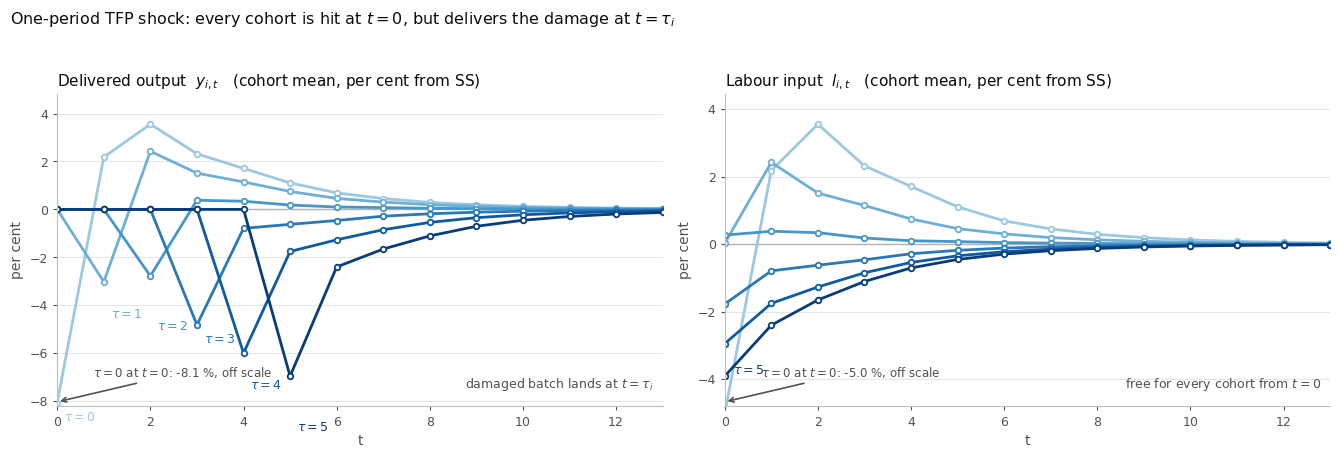

Output, per cent from the steady state  (0.0000 = still delivering pre-shock goods)


,Y %,tau=0,tau=1,tau=2,tau=3,tau=4,tau=5
t,,,,,,,
0,-0.0740,-8.0560,0.0000,0.0000,0.0000,-0.0000,-0.0000
1,-0.6335,2.1814,-3.0211,0.0000,0.0000,-0.0000,-0.0000
2,-0.6604,3.5553,2.4241,-2.7784,0.0000,-0.0000,-0.0000
3,-0.4336,2.3194,1.5137,0.3826,-4.8199,-0.0000,-0.0000
4,-0.3032,1.7107,1.1460,0.3403,-0.7908,-5.9933,-0.0000
5,-0.1961,1.1061,0.7468,0.1821,-0.6236,-1.7547,-6.9572
6,-0.1243,0.6892,0.4601,0.1009,-0.4638,-1.2695,-2.4006
7,-0.0816,0.4531,0.3047,0.0756,-0.2836,-0.8483,-1.6540
8,-0.0529,0.2913,0.1948,0.0464,-0.1827,-0.5419,-1.1066


In [8]:
COHORTS = list(range(6))                     # tau = 0..5 is 261 of the 269 producers
ramp    = plt.cm.Blues(np.linspace(0.38, 0.95, len(COHORTS)))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
fig.patch.set_facecolor('white')
for ax, key, base, name, note in [
        (axes[0], 'y', ss0['y'], r'Delivered output  $y_{i,t}$',
         'damaged batch lands at $t=\\tau_i$'),
        (axes[1], 'l', ss0['l'], r'Labour input  $l_{i,t}$',
         'free for every cohort from $t=0$')]:
    style(ax)
    V = {k: 100 * np.log(sol[key][:, TVALS == k].mean(axis=1) / base[TVALS == k].mean())[:H]
         for k in COHORTS}
    rest = np.concatenate([v[1:] if k == 0 else v for k, v in V.items()])
    lo, hi = rest.min(), rest.max(); pad = 0.12 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)
    for j, (col, k) in enumerate(zip(ramp, COHORTS)):
        v = V[k]
        ax.plot(t, v, color=col, lw=2.0, marker='o', ms=4, markerfacecolor='white',
                markeredgecolor=col, markeredgewidth=1.3)
        if key == 'y':
            ax.annotate(rf'$\tau={k}$', xy=(k, v[k]), xytext=(5, -13 - 13 * (j % 3)),
                        textcoords='offset points', fontsize=9, color=col)
        elif k in (0, COHORTS[-1]):
            ax.annotate(rf'$\tau={k}$', xy=(0, v[0]), xytext=(6, 2),
                        textcoords='offset points', fontsize=9, color=col)
    ax.annotate(rf'$\tau=0$ at $t=0$: {V[0][0]:.1f} %, off scale',
                xy=(0, lo - pad * 0.85), xytext=(26, 18), textcoords='offset points',
                fontsize=8.5, color=MUTED,
                arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))
    ax.set_title(name + '   (cohort mean, per cent from SS)', color=INK, fontsize=11, loc='left')
    ax.set_ylabel('per cent', color=MUTED)
    ax.text(0.985, 0.06, note, transform=ax.transAxes, ha='right', fontsize=9, color=MUTED)

fig.suptitle('One-period TFP shock: every cohort is hit at $t=0$, but delivers the damage at '
             r'$t=\tau_i$', fontsize=11.5, color=INK, x=0.011, ha='left', y=1.03)
fig.tight_layout()
fig.savefig('../ss_A_cohort_firms.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

coh = pd.DataFrame({f'tau={k}': 100 * np.log(sol['y'][:, TVALS == k].mean(axis=1)
                                             / ss0['y'][TVALS == k].mean()) for k in COHORTS},
                   index=pd.Index(range(T), name='t')).iloc[:9]
coh.insert(0, 'Y %', 100 * np.log(sol['Y'] / ss0['Y'])[:9])
print('Output, per cent from the steady state  (0.0000 = still delivering pre-shock goods)')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(coh)

## 7. When does the damage arrive?

Cohort $\tau_i=k$ delivers its damaged batch at $t=k$, so the *exposure* of date $t$ is the
share of output produced by cohort $\tau_i=t$ — read straight off the calibrated inventory
distribution.  The realised output path is flatter than that exposure profile, because the
household smooths: consumption is spread beyond the dates the goods actually go missing.

,producers with tau = t,exposure: share of Y delivered by that cohort %,Y response %,share of the total response %
t,,,,
0,1,0.949,-0.074,2.782
1,31,21.867,-0.633,23.800
2,97,44.698,-0.660,24.814
3,66,20.290,-0.434,16.291
4,48,9.626,-0.303,11.392
5,18,2.332,-0.196,7.368
6,1,0.079,-0.124,4.672
7,2,0.092,-0.082,3.067
8,0,0.000,-0.053,1.988


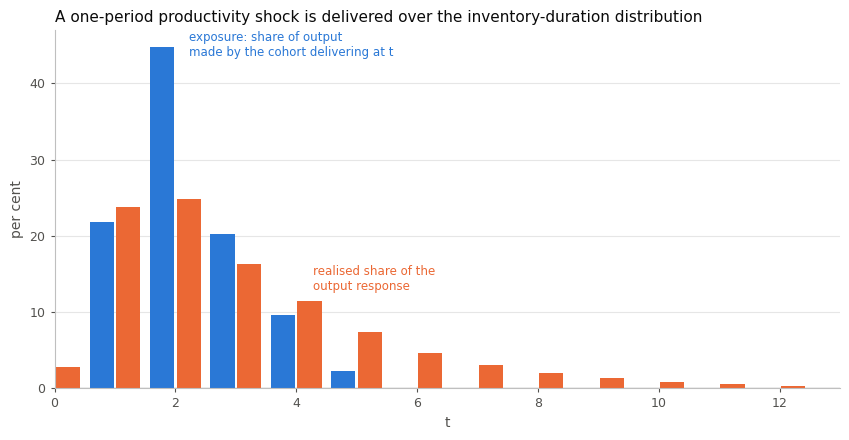

In [9]:
K = TVALS.max() + 1
exposure = np.array([ss0['q'][TVALS == k] @ ss0['y'][TVALS == k] / ss0['Y'] for k in range(K)])
dY  = np.log(sol['Y'] / ss0['Y'])
tab = pd.DataFrame({
    'producers with tau = t':  [int(np.sum(TVALS == k)) for k in range(K)],
    'exposure: share of Y delivered by that cohort %': 100 * exposure,
    'Y response %':            100 * dY[:K],
    'share of the total response %': 100 * dY[:K] / dY.sum(),
}, index=pd.Index(range(K), name='t'))
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(tab.iloc[:9])

fig, ax = plt.subplots(figsize=(8.6, 4.5))
fig.patch.set_facecolor('white'); style(ax)
w = 0.4
ax.bar(np.arange(K)[:H] - w/2 - 0.02, 100 * exposure[:H], width=w, color=BLUE, linewidth=0)
ax.bar(np.arange(K)[:H] + w/2 + 0.02, 100 * dY[:K][:H] / dY.sum(), width=w, color=ORANGE,
       linewidth=0)
ax.annotate('exposure: share of output\nmade by the cohort delivering at t', xy=(2, 100*exposure[2]),
            xytext=(10, -6), textcoords='offset points', fontsize=8.5, color=BLUE)
ax.annotate('realised share of the\noutput response', xy=(4, 100*dY[4]/dY.sum()),
            xytext=(12, 8), textcoords='offset points', fontsize=8.5, color=ORANGE)
ax.set_ylabel('per cent', color=MUTED)
ax.set_title('A one-period productivity shock is delivered over the inventory-duration '
             'distribution', color=INK, fontsize=11, loc='left')
fig.tight_layout()
fig.savefig('../ss_A_timing.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## Caveats

* $\Delta_i$ is held at its steady-state value.  For an $A$ shock this is weaker than it
  sounds — $A_t$ drops out of the delay's first-order condition entirely — but the induced path
  of demand would still move $\Delta_i$ a little.
* "Unexpected" means dates before 0 were not conditioned on the shock; from $t=0$ it is perfect
  foresight, so producers hiring at $t=0$ know their productivity is low and that it recovers
  at $t=1$.
* The nominal side is left implicit.  It is recoverable — pick any nominal anchor, e.g.
  $i_t=\rho$ and $W_T=1$ — but it is neutral for everything above, which is why the solver
  works in real terms.
* A $B_t$ shock is not covered: $B$ enters $(\Delta+B_tN_i)$, so it changes the optimal delay,
  and the fixed-$\tau$ assumption would be doing real work.